---
title: Week 4 Challenge 1 KEY
subtitle: DS 2023 | Communicating with Data
---

## Overview

In today's challenge, you will apply what you have learned about area and difference charts in [the course book](https://ontoligent.github.io/DS2023/area-charts/).

Use the notebook as your guide.

Work in groups to perform the tasks.

When finished, submit a URL to this notebook in your GitHub repo to today's participation assignment.

## The data set

Today's dataset comes from the **US Department of Agrigulture, Economic Research Service**. 

It contains US import and export data of agricultural products from 1975 to 2026.

Below is an exceprt from the the analysis of the data provided by the service:

<table>
    <tr>
        <td style="width:50%;">
            <img src="https://www.ers.usda.gov/media/21909/58310-chart-image-file.png"/>                    
        </td>
        <td style="width:50%;font-size:12pt;font-family:serif;">
            <p>The U.S. agricultural trade balance was positive for nearly 60 years until 2019, when the balance began shifting to a deficit. By 2025, U.S. agricultural imports grew to exceed exports by $41 billion. U.S. agricultural exports grew at a compound annual growth rate of 2.3 percent between 2015 and 2025—with growing global competition, a strong dollar, and trade barriers all posing headwinds to export growth. In comparison, U.S. agricultural imports have largely followed a more stable upward trend, growing at a rate of 5.8 percent between 2015 and 2025. U.S. agricultural imports have been driven by: a strong U.S. economy, the strength of the dollar, and a robust and increasingly diverse appetite of the U.S. consumer. Much of the U.S. agricultural import growth has come from high-valued imported goods—such as fruits and vegetables, alcoholic beverages, and processed food products. Those goods often include products that can’t be easily or economically produced in the United States (such as tropical products or off-season produce), as well as labor-intensive products that can be comparatively more cost effective to produce in other countries. In 2025, U.S. agricultural imports fell slightly, slowing in the second half of the year, partially in response to new tariff policies.</p>
            <br/>
        <p>&mdash; <a href="https://www.ers.usda.gov/data-products/ag-and-food-statistics-charting-the-essentials/agricultural-trade" target="_blank">See "U.S. agricultural import values outpaced export values in 2025"</a></p>
        </td>
    </tr>
    </div>
</div>

<b style="clear:both;">Resources</b>

- [CSV](https://www.ers.usda.gov/media/5035/total-value-of-us-agricultural-trade-and-trade-balance-monthly.xlsx?v=31554)
- [Metadata](https://www.ers.usda.gov/data-products/foreign-agricultural-trade-of-the-united-states-fatus/us-agricultural-trade-data-update)
- [Analysis](https://www.ers.usda.gov/data-products/ag-and-food-statistics-charting-the-essentials/agricultural-trade)


## Tasks

Emulate the two plots shown above. 

### Set Up

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

First, we import and clean up a modified version of the data. 

In [3]:
data_url = "https://virginia.box.com/shared/static/gpe5k1z8jzwk7e7odb2sc9xo7bol84n3.csv"

usda = pd.read_csv(data_url)

# Lower case columns and convert spaces to underscores
usda.columns = [col.lower().replace(" ", "_") for col in usda.columns]

# Set index to year and month 
usda = usda.set_index(['year','month'])

# Replace commas in remaining columns and convert to integers
for col in ['exports','imports','trade_balance']:
    usda[col] = usda[col].str.replace(",","").astype(int)

# Show results
usda.info()
usda.head()

<class 'pandas.DataFrame'>
MultiIndex: 610 entries, (np.int64(1975), 'October') to (np.int64(2026), 'July')
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   exports        610 non-null    int64
 1   imports        610 non-null    int64
 2   trade_balance  610 non-null    int64
dtypes: int64(3)
memory usage: 16.2 KB


exports    imports  trade_balance
year month                                         
1975 October   2107269698  772419243     1334850455
     November  2189295521  745292845     1444002676
     December  1981702692  712332124     1269370568
1976 January   2018084929  756591083     1261493846
     February  1757878644  718538213     1039340431

### Task 1

Plot a line graph of the `exports` and `imports`.

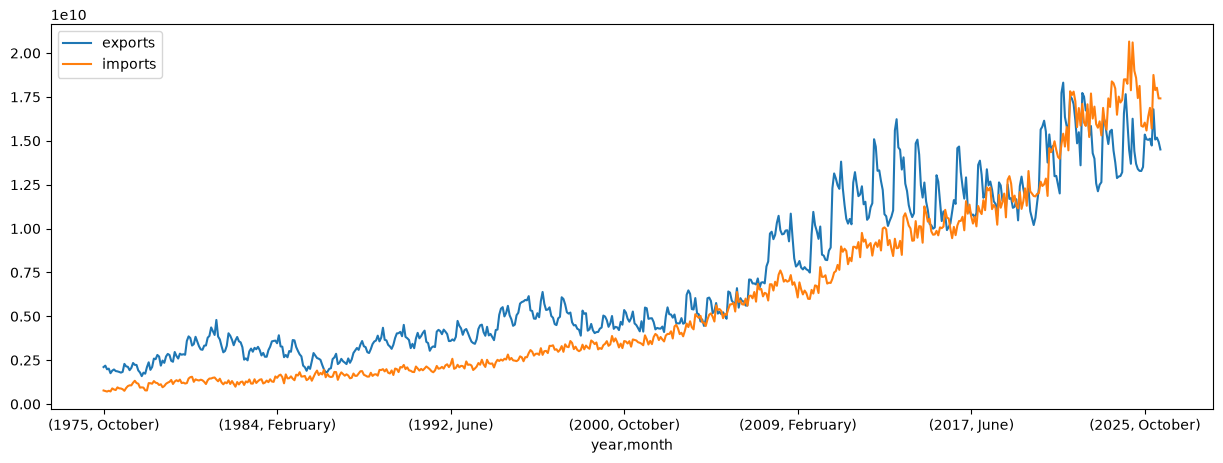

In [4]:
usda[['exports','imports']].plot(figsize=(15,5))
plt.show()

### Task 2

Create a dataframe that groups by year and gets the sum of the measurement variables between 2005 and 2025 inclusive.

In [5]:
usda_years = usda.query("year >= 2005 and year < 2026").groupby('year').sum()
usda_years.head()

,exports,imports,trade_balance
year,,,
2005,65550334061,63268060159,2282273902
2006,73624134978,70453264700,3170870278
2007,93099308443,76929731969,16169576474
2008,117710084633,85192398972,32517685661
2009,100763472337,76720252907,24043219430


### Task 3 

Plot an area chart of of `imports` and `exports`.

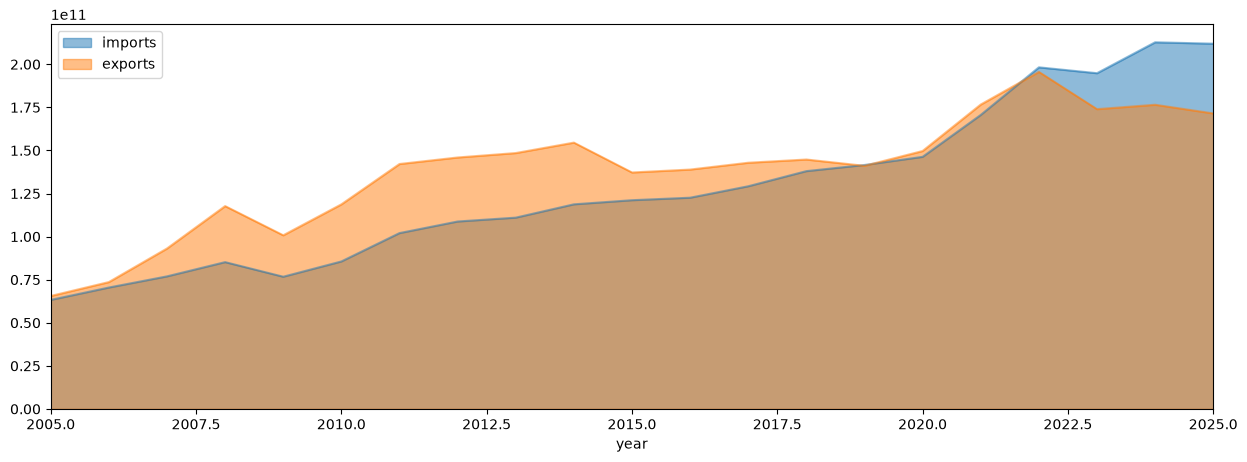

In [6]:
usda_years[['imports','exports']].plot.area(stacked=False, figsize=(15,5), xlim=(2005, 2025))
plt.show()

### Task 4

Using the pattern from the model notebook, create a difference chart from the same data.

In [7]:
usda_years['min'] = usda_years[['exports', 'imports']].min(axis=1)
usda_years.head()

,exports,imports,trade_balance,min
year,,,,
2005,65550334061,63268060159,2282273902,63268060159
2006,73624134978,70453264700,3170870278,70453264700
2007,93099308443,76929731969,16169576474,76929731969
2008,117710084633,85192398972,32517685661,85192398972
2009,100763472337,76720252907,24043219430,76720252907


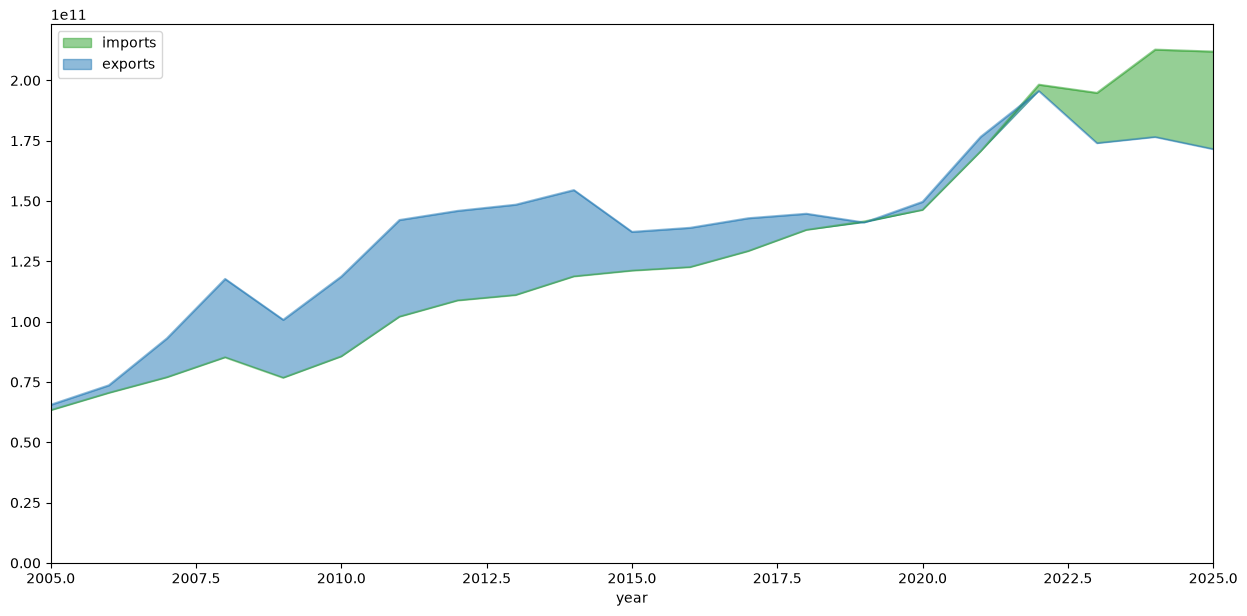

In [8]:
ax = usda_years[['imports','exports']].plot.area(stacked=False, figsize=(15,7), xlim=(2005,2025), color=['tab:green', 'tab:blue'])
usda_years['min'].plot.area(ax=ax, color='white', lw=0)
plt.show()

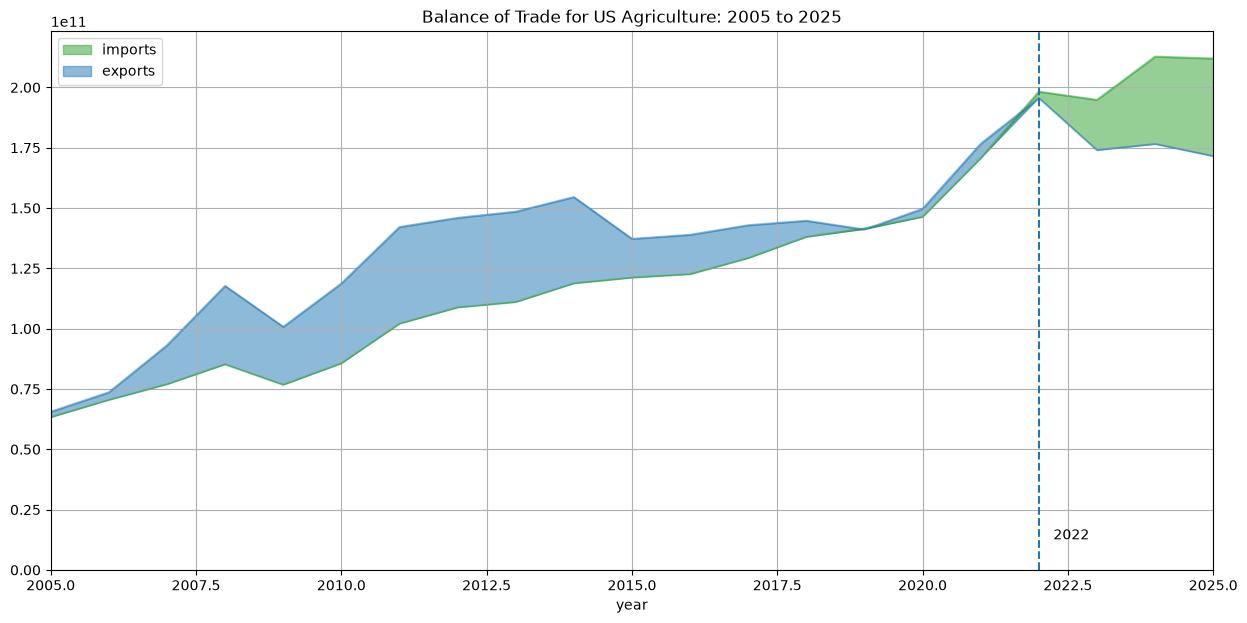

In [9]:
ax = usda_years[['imports','exports']].plot.area(stacked=False, 
                                                 figsize=(15,7), 
                                                 xlim=(2005,2025), 
                                                 color=['tab:green', 'tab:blue'])
usda_years['min'].plot.area(ax=ax, color='white', lw=0)
ax.axvline(2022, ls='--')
ax.text(2022.25, 1.27 * 10**10, "2022")
ax.grid()
plt.title("Balance of Trade for US Agriculture: 2005 to 2025")
plt.show()

### Task 5 

Create a bar chart of `trade_balance` over the same period.

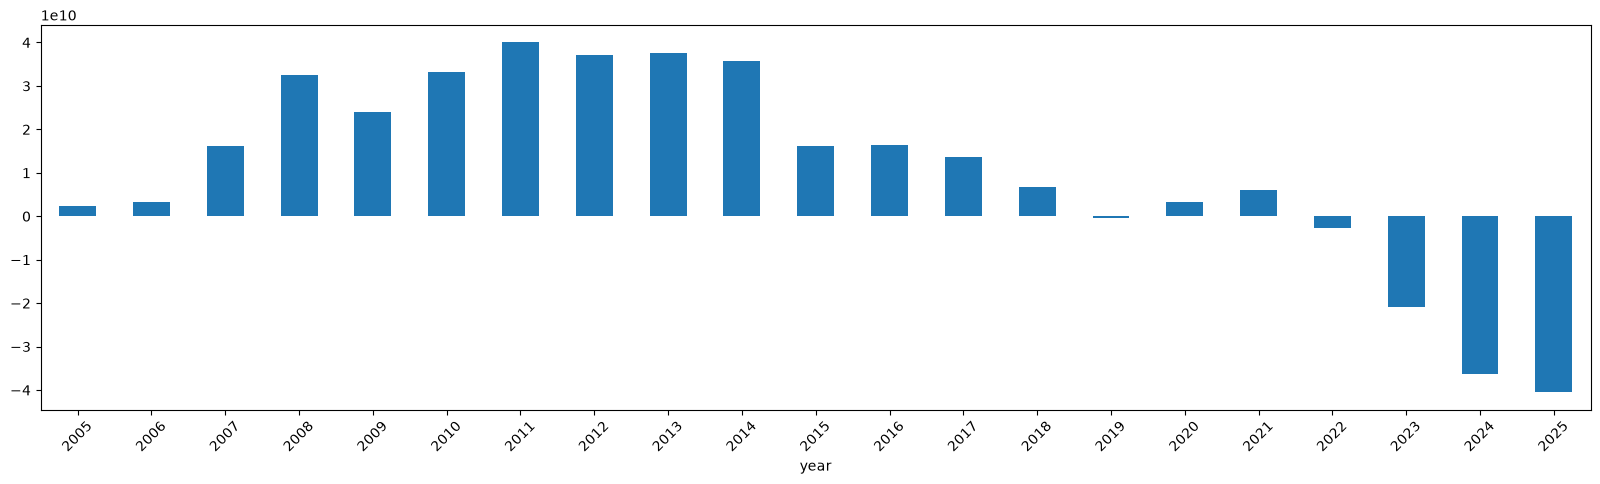

In [10]:
usda_years['trade_balance'].plot.bar(rot=45, figsize=(20, 5))
plt.show()

### Bonus

Combine the two plots into a single figure.

Hint: Create figure object with two axes objects using the following code snippet:

```python
fig, ax = plt.subplots(2, 1, figsize=(20, 10))
```

Then park the two plots in the two axes, i.e. `ax[0]` and `ax[1]`.

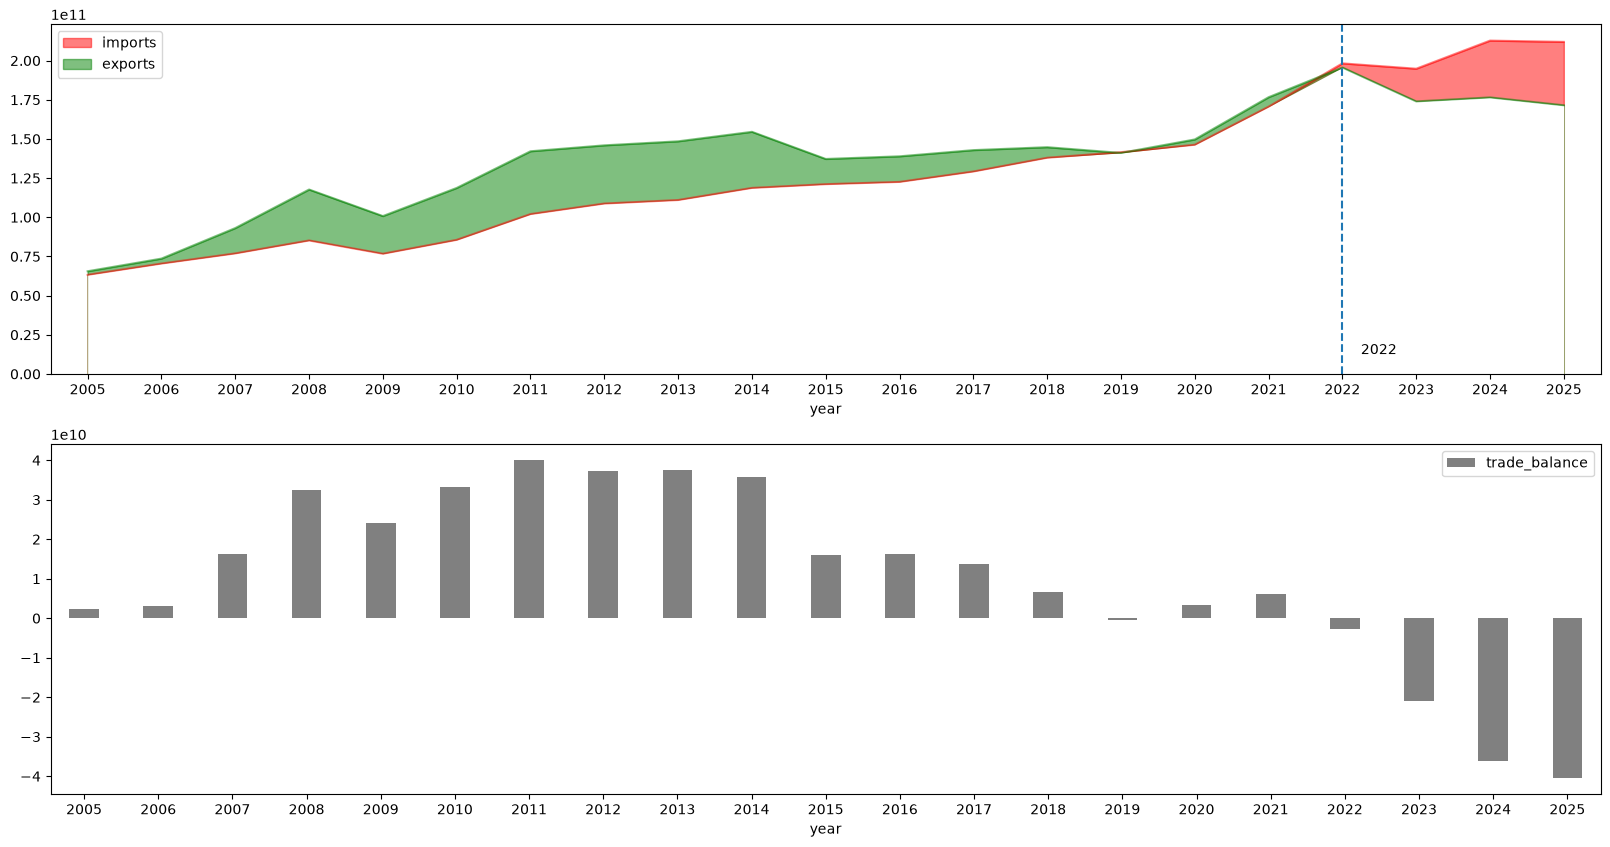

In [11]:
fig, ax = plt.subplots(2, 1, figsize=(20, 10), sharex=False, sharey=False)

# Area chart
usda_years[['imports','exports']].plot.area(ax=ax[0], stacked=False, xlim=(2004.5,2025.5), color=['red', 'green'])
usda_years['min'].plot.area(ax=ax[0], color='white', lw=0)

# Vertical line
ax[0].axvline(2022, ls='--')
ax[0].text(2022.25, 1.27 * 10**10, "2022")

# xtick labels
ax[0].set_xticks(usda_years.index)

# Bar chart
usda_years[['trade_balance']].plot.bar(ax=ax[1], rot=0, width=.4, color='grey')

plt.show()

Here is a way to combine the images in one axes.

To do this, it is more effective to produce the bar chart in Matplotlib.

In [78]:
# ax.bar?

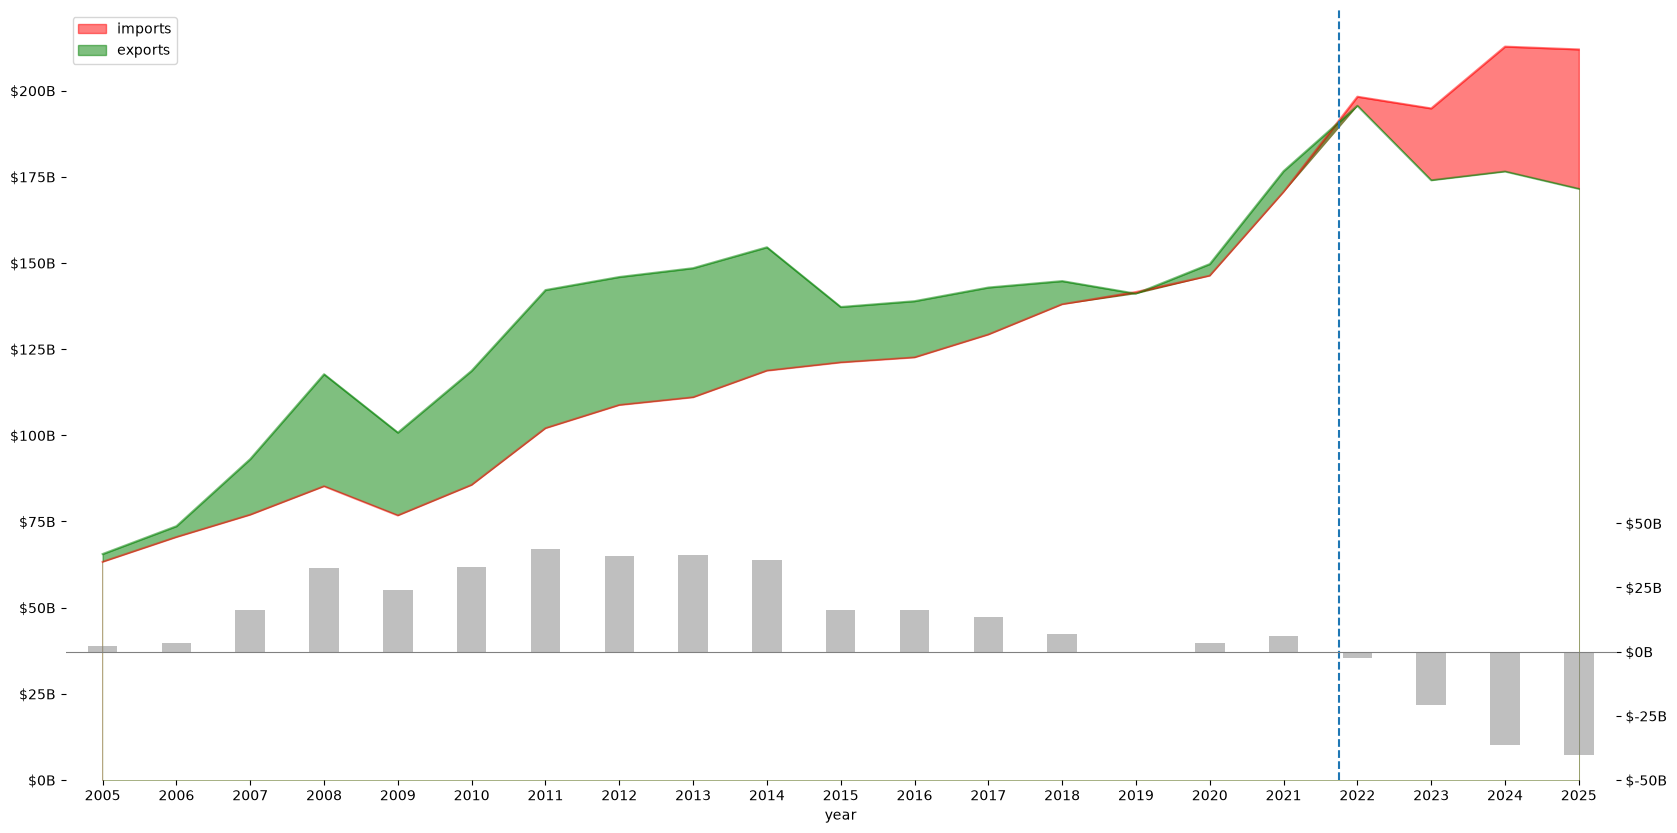

In [98]:
# Area chart
ax = usda_years[['imports','exports']].plot.area(
    stacked=False, xlim=(2004.5, 2025.5), color=['red', 'green'], figsize=(20, 10))

# Mask
usda_years['min'].plot.area(ax=ax, color='white', lw=0)

# Vertical line
ax.axvline(2021.75, ls='--')

# Bar chart 
ax1 = ax.twinx()
ax1.bar(x=usda_years.index, height=usda_years['trade_balance'], width=0.4, color='grey', alpha=.5)
ax1.set_ylim((-50_000_000_000, 250_000_000_000))
ax1.set_yticks(np.arange(-50e9, 50e9 + 1, 25e9))   # -50B, -25B, 0, 25B, 50B

# xtick labels (set last so nothing overwrites them)
ax.set_xticks(usda_years.index)
ax.set_xlim(2004.5, 2025.5)

# Converts the tick labels to readable numbers
from matplotlib.ticker import FuncFormatter
billions = FuncFormatter(lambda x, _: f'${x/1e9:,.0f}B')
ax.yaxis.set_major_formatter(billions)
ax1.yaxis.set_major_formatter(billions)

# Gives the bar chart a base line
ax1.axhline(0, color='grey', lw=0.8)

# Removes the spines, including the left and bottom ones
sns.despine(left=True, bottom=True)

plt.show()

And, finally, this one uses Matplotlib's `fill_between` function, which creates the difference chart in a more direct way.

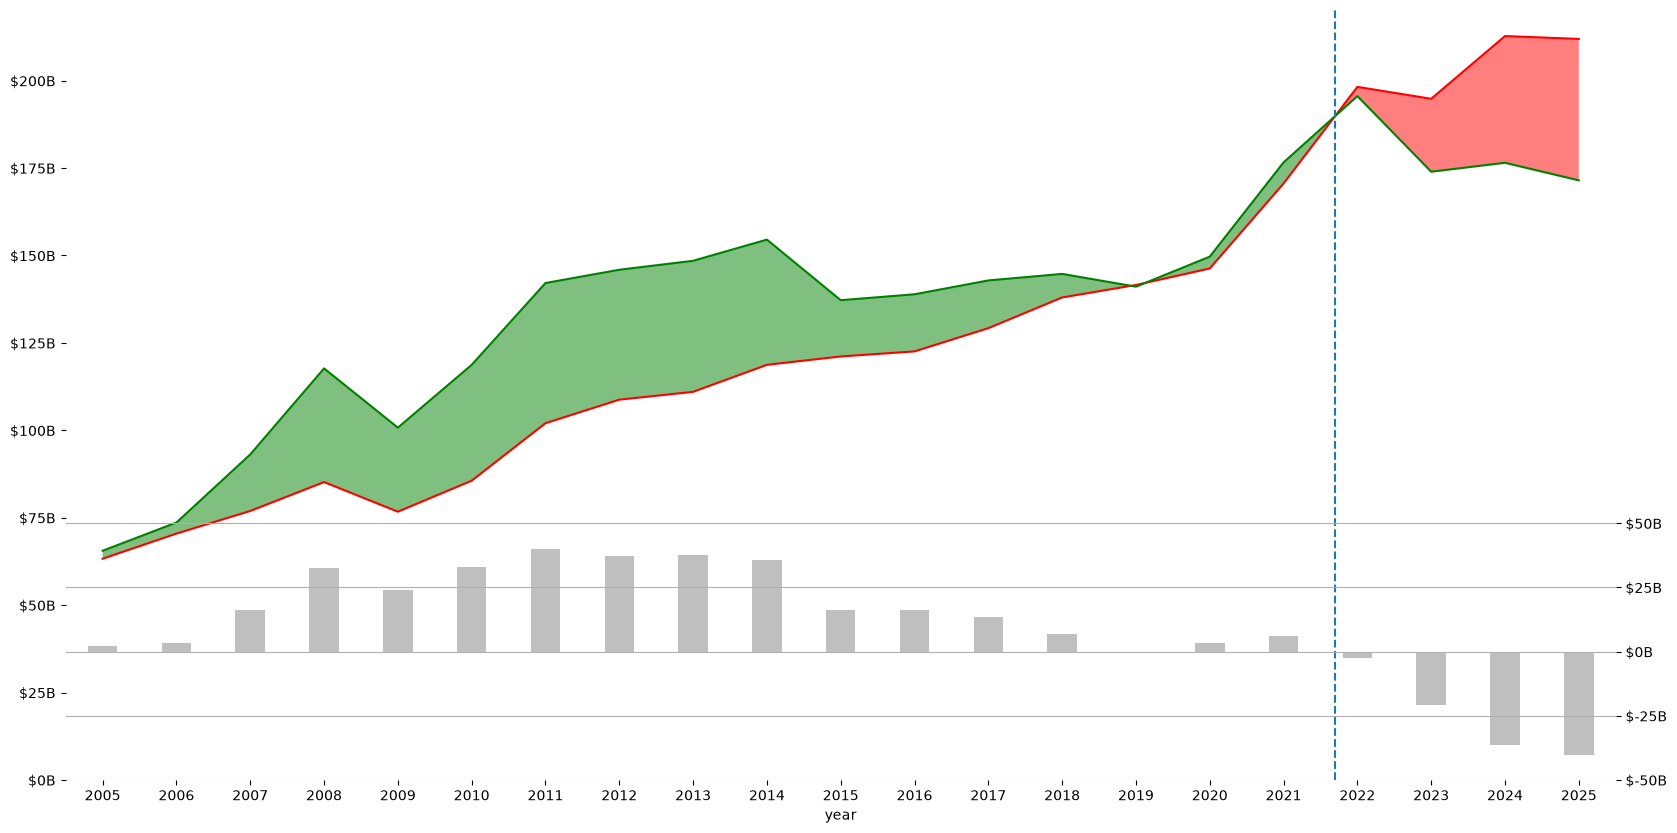

In [118]:
# Grab the series we need to use directly in axes object method arguments 
x   = usda_years.index
imp = usda_years['imports']
exp = usda_years['exports']

# Create the canvas
fig, ax = plt.subplots(figsize=(20, 10))

# Draw line plots for the two variables
ax.plot(x, imp, color='red', lw=1.5, label='imports')
ax.plot(x, exp, color='green', lw=1.5, label='exports')

# Create a shaded gap between the lines using fill_between
# Note the argument 'where'
ax.fill_between(x, imp, exp, where=exp >= imp, interpolate=True, color='green', alpha=0.5, lw=0, label='exports > imports')
ax.fill_between(x, imp, exp, where=imp > exp, interpolate=True, color='red', alpha=0.5, lw=0, label='imports > exports')

# Set the x axis limits and values
ax.set_xlim(2004.5, 2025.5)
ax.set_ylim(0)          
ax.set_xticks(x)
ax.set_xlabel('year')

# ax.grid(axis='y', color='lightgrey', lw=0.8)

# Put par chart on twinned axes object (with shared x)
# Here we use Matplotlib's bar method, not Pandas, to prevent Pandas from overwriting the axes object
ax1 = ax.twinx()
ax1.bar(x=usda_years.index, height=usda_years['trade_balance'], width=0.4, color='grey', alpha=.5)

# Set a y limit so that only the relevant domain shows up on the right
ax1.set_ylim((-50_000_000_000, 250_000_000_000))
ax1.set_yticks(np.arange(-50e9, 50e9 + 1, 25e9))   # -50B, -25B, 0, 25B, 50B

# Set xtick labels (we do this last so nothing overwrites them)
ax.set_xticks(usda_years.index)
ax.set_xlim(2004.5, 2025.5)

# Format the numbers
from matplotlib.ticker import FuncFormatter
billions = FuncFormatter(lambda x, _: f'${x/1e9:,.0f}B')
ax.yaxis.set_major_formatter(billions)
ax1.yaxis.set_major_formatter(billions)

# Plot a grid (for the bar chart)
plt.grid()

# Remove spines 
sns.despine(left=True, bottom=True)


# Vertical line
ax.axvline(2021.7, ls='--')


plt.show()

## Using fill between with Pandas lines

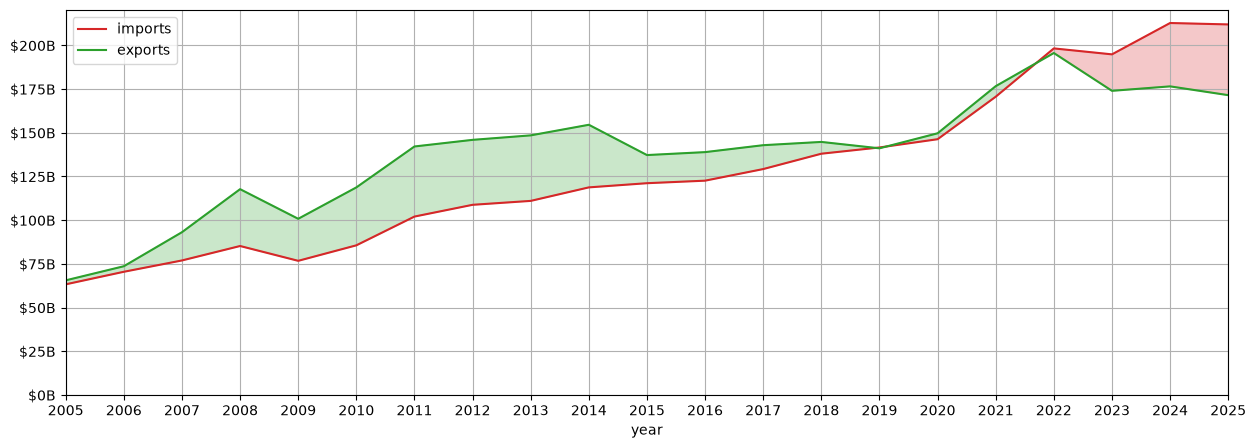

In [170]:
# Create line plots
ax = usda_years[['imports','exports']].plot(figsize=(15,5), xlim=(2005, 2025), ylim=(0, None), color=['tab:red','tab:green'])

# Use Matplotlib's fill_between to do the work
yrs = usda_years.index
imp = usda_years['imports']
exp = usda_years['exports']
ax.fill_between(x=yrs, y1=imp, y2=exp, where=(exp > imp), interpolate=True, color='tab:green', alpha=0.25)
ax.fill_between(x=yrs, y1=imp, y2=exp, where=(imp >= exp), interpolate=True, color='tab:red', alpha=0.25)

ax.set_xticks(yrs)
ax.yaxis.set_major_formatter(billions)

plt.grid()
plt.show()

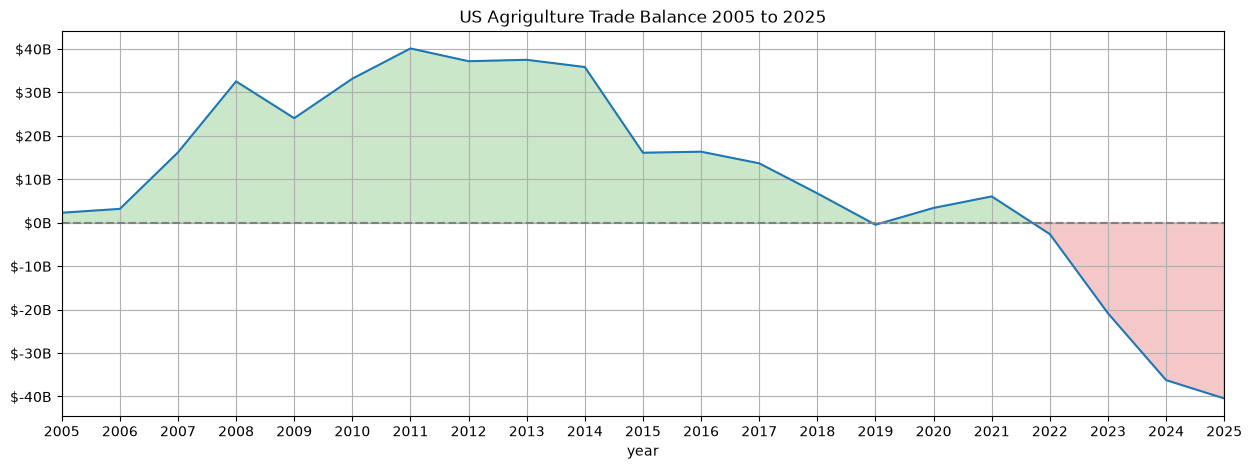

In [171]:
ax2 = usda_years.trade_balance.plot(xlim=(2005,2025), figsize=(15,5), rot=0)
ax2.axhline(0, c='gray', ls='--')
tbal = usda_years.trade_balance
ax2.fill_between(x=yrs, y1=0, y2=tbal, where=(tbal > 0), interpolate=True, color='tab:green', alpha=0.25)
ax2.fill_between(x=yrs, y1=0, y2=tbal, where=(tbal <= 0), interpolate=True, color='tab:red', alpha=0.25)
ax2.set_xticks(yrs)
ax2.yaxis.set_major_formatter(billions)
plt.grid()
plt.title("US Agrigulture Trade Balance 2005 to 2025")
plt.show()

### Explanation

In 2022, U.S. agricultural trade reached record highs in value driven by surging global commodity prices, despite lower overall export volumes caused by supply chain hurdles, weather events, and geopolitical conflict. [1, 2] 

## Key Factors Affecting 2022 Ag Trade

* **The Russia-Ukraine War**: Russia's invasion of Ukraine in February 2022 disrupted major global grain and oilseed supplies, driving international commodity prices significantly higher. [1, 2] 
* **Global Supply Chain and Input Costs**: Surging energy, transportation, and fertilizer costs added inflationary pressure, boosting the dollar value of traded goods even as shipping volumes tightened. [1, 2] 
* **Weather Extremes**: Northern Hemisphere droughts in 2021 and the severe 2022 Mississippi River drought constrained domestic and regional crop transport, affecting localized shipping and input pricing. [1, 3] 
* **Surging Import Demand and Prices**: High global demand—especially from top markets like China—pushed U.S. agricultural export values to a record \$196 billion. Simultaneously, U.S. agricultural imports jumped 16% (nearly \$28 billion), resulting in a rare annual trade deficit of \$3 billion. [1, 4, 5] 

You can read the detailed breakdown of bulk commodity trends from the [Foreign Agricultural Service](https://www.fas.usda.gov/data/rise-and-fall-bulk-commodities-share-total-us-agricultural-exports). [1] 
If you'd like, I can provide more details on:

* Specific performance numbers for top exported commodities (like soybeans or corn) in 2022
* How trade deficits evolved in subsequent years


[1] [https://www.fas.usda.gov](https://www.fas.usda.gov/data/rise-and-fall-bulk-commodities-share-total-us-agricultural-exports)\
[2] [https://agecon.mgcafe.uky.edu](https://agecon.mgcafe.uky.edu/us-ag-exportstrade-policy-update-june-2022)\
[3] [https://onlinelibrary.wiley.com](https://onlinelibrary.wiley.com/doi/10.1002/agr.21880)\
[4] [https://www.fb.org](https://www.fb.org/intel/markets/record-numbers-not-the-only-striking-thing-about-2022-u-s-ag-trade)\
[5] [https://www.usda.gov](https://www.usda.gov/about-usda/news/press-releases/2023/02/10/2022-was-another-record-year-us-farm-exports)

From [Google AI](https://share.google/aimode/8gBRZlEar7zNWFk4P)